<a href="https://colab.research.google.com/github/MasHudaaa/Praktikum1-ComputerVision/blob/main/Praktikum_CV_Kel_Fattah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!unzip Dataseet-Kurma.zip

Archive:  Dataseet-Kurma.zip
   creating: Dataseet-Kurma/
   creating: Dataseet-Kurma/kurma azwa/
  inflating: Dataseet-Kurma/kurma azwa/kurma azwa-1.jpeg  
  inflating: Dataseet-Kurma/kurma azwa/kurma azwa-2.jpeg  
  inflating: Dataseet-Kurma/kurma azwa/kurma azwa-3.jpeg  
  inflating: Dataseet-Kurma/kurma azwa/kurma azwa-4.jpeg  
  inflating: Dataseet-Kurma/kurma azwa/kurma azwa-5.jpeg  
   creating: Dataseet-Kurma/kurma medjoul/
  inflating: Dataseet-Kurma/kurma medjoul/kurma medjoul-1.jpeg  
  inflating: Dataseet-Kurma/kurma medjoul/kurma medjoul-2.jpeg  
  inflating: Dataseet-Kurma/kurma medjoul/kurma medjoul-3.jpeg  
  inflating: Dataseet-Kurma/kurma medjoul/kurma medjoul-4.jpeg  
  inflating: Dataseet-Kurma/kurma medjoul/kurma medjoul-5.jpeg  
   creating: Dataseet-Kurma/kurma sukari/
  inflating: Dataseet-Kurma/kurma sukari/kurma sukari-1.jpeg  
  inflating: Dataseet-Kurma/kurma sukari/kurma sukari-2.jpeg  
  inflating: Dataseet-Kurma/kurma sukari/kurma sukari-3.jpeg  
  inflat

In [5]:
import os

# Cek folder di /content
print("Isi folder:", os.listdir('/content'))

# Cek folder dataset yang diekstrak (sesuaikan nama folder jika berbeda)
dataset_path = '/content/Dataseet-Kurma'
if os.path.exists(dataset_path):
    print("Kategori kurma:", os.listdir(dataset_path))

Isi folder: ['.config', 'Dataseet-Kurma', 'Dataseet-Kurma.zip', 'sample_data']
Kategori kurma: ['kurma sukari', 'kurma medjoul', 'kurma azwa']


In [6]:
import tensorflow as tf

dataset_path = '/content/Dataseet-Kurma'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load Data Latih (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Load Data Validasi (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Kelas kurma yang terdeteksi:", class_names)

Found 15 files belonging to 3 classes.
Using 12 files for training.
Found 15 files belonging to 3 classes.
Using 3 files for validation.
Kelas kurma yang terdeteksi: ['kurma azwa', 'kurma medjoul', 'kurma sukari']


In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Optimasi Data
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# 2. Tambahkan Data Augmentation (Mencegah model bingung karena data sedikit)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
])

# 3. Load Base Model MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Buka beberapa layer atas untuk Fine-Tuning
base_model.trainable = True
fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# 4. Susun Arsitektur Model Baru
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./255),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation='softmax')
])

# 5. Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 6. Latih Ulang Model selama 25 Epoch
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25
)

Epoch 1/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step - accuracy: 0.3333 - loss: 1.1947 - val_accuracy: 0.0000e+00 - val_loss: 1.9507
Epoch 2/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 951ms/step - accuracy: 0.5000 - loss: 1.1312 - val_accuracy: 0.0000e+00 - val_loss: 1.9397
Epoch 3/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 941ms/step - accuracy: 0.7500 - loss: 0.7277 - val_accuracy: 0.0000e+00 - val_loss: 1.9448
Epoch 4/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 955ms/step - accuracy: 0.9167 - loss: 0.5005 - val_accuracy: 0.0000e+00 - val_loss: 1.9037
Epoch 5/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 952ms/step - accuracy: 0.5000 - loss: 0.9654 - val_accuracy: 0.0000e+00 - val_loss: 1.8001
Epoch 6/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 955ms/step - accuracy: 0.6667 - loss: 0.6474 - val_accuracy: 0.0000e+00 - val_loss: 1.6853
Epoch 7/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5833 - loss: 0.7331 - val_accuracy: 0.0000e+00 - val_loss: 1.5573
Epoch 8/25
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 954ms/step - accuracy: 0.9167 - loss: 0.3546 - val_accu

In [27]:
import numpy as np
import tensorflow as tf

# GANTI DI SINI (Tambahkan nama file gambarnya di ujung):
sample_img_path = '/content/Dataseet-Kurma/kurma sukari/kurma sukari-6.jpg'

# 1. Load dan sesuaikan ukuran gambar
img = tf.keras.utils.load_img(sample_img_path, target_size=(224, 224))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)

# 2. Jalankan prediksi
predictions = model.predict(img_array)
predicted_class = class_names[np.argmax(predictions[0])]
confidence = 100 * np.max(predictions[0])

# 3. Tampilkan hasil
print(f"File yang diuji: {sample_img_path}")
print(f"Hasil Prediksi: {predicted_class} ({confidence:.2f}%)")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
File yang diuji: /content/Dataseet-Kurma/kurma sukari/kurma sukari-6.jpg
Hasil Prediksi: kurma medjoul (48.82%)


=== 1. INFORMASI UKURAN & TIPE DATA CITRA MEDJOUL ===
Citra 1 (Dataseet-Kurma/kurma azwa/kurma azwa-1.jpeg):
  - Ukuran (Shape) : (720, 720, 3) (Tinggi x Lebar x Kanal)
  - Tipe Data      : uint8
  - Pencahayaan    : Cahaya Lampu Indoor (Terang dari Atas)

Citra 2 (Dataseet-Kurma/kurma azwa/kurma azwa-2.jpeg):
  - Ukuran (Shape) : (720, 720, 3) (Tinggi x Lebar x Kanal)
  - Tipe Data      : uint8
  - Pencahayaan    : Cahaya Alami Siang Hari (Samping Jendela)

Citra 3 (Dataseet-Kurma/kurma medjoul/kurma medjoul-3.jpeg):
  - Ukuran (Shape) : (720, 720, 3) (Tinggi x Lebar x Kanal)
  - Tipe Data      : uint8
  - Pencahayaan    : Cahaya Lampu Meja (Fokus Samping)

Citra 4 (Dataseet-Kurma/kurma medjoul/kurma medjoul-4.jpeg):
  - Ukuran (Shape) : (720, 720, 3) (Tinggi x Lebar x Kanal)
  - Tipe Data      : uint8
  - Pencahayaan    : Cahaya Tambahan (Flash Kamera)

Citra 5 (Dataseet-Kurma/kurma sukari/kurma sukari-1.jpeg):
  - Ukuran (Shape) : (720, 720, 3) (Tinggi x Lebar x Kanal)
  - Tipe Data

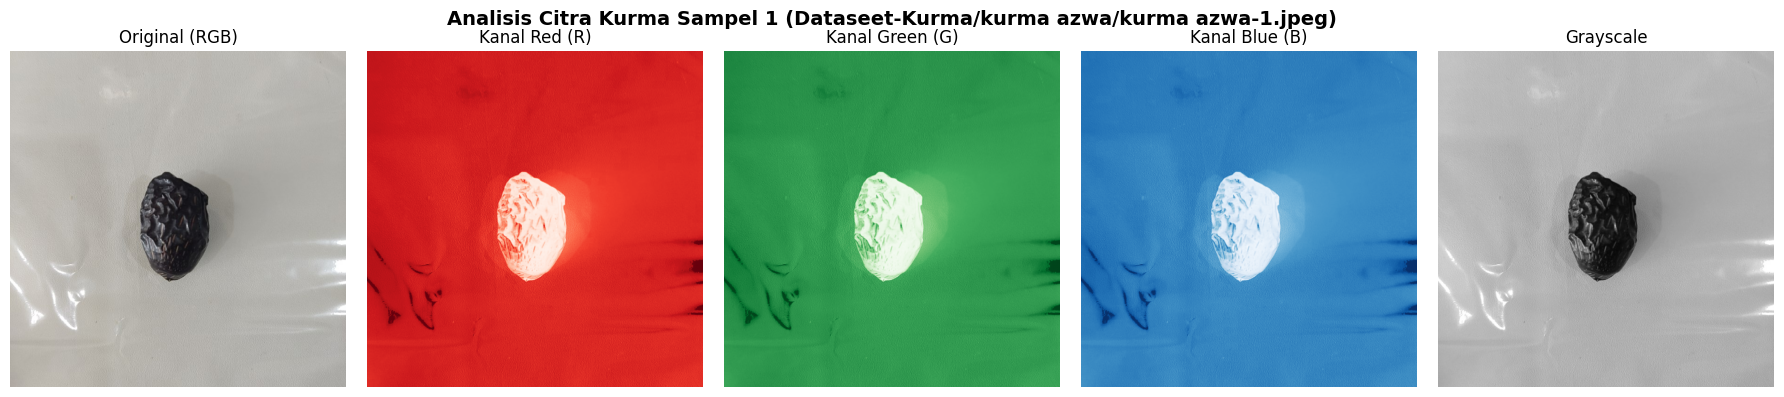

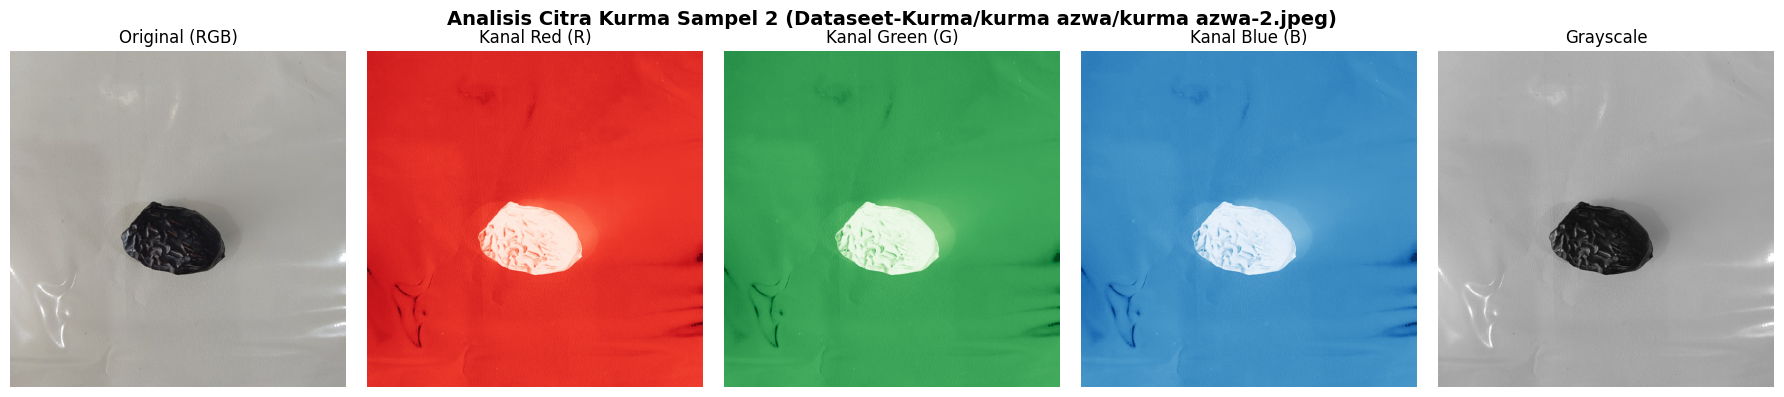

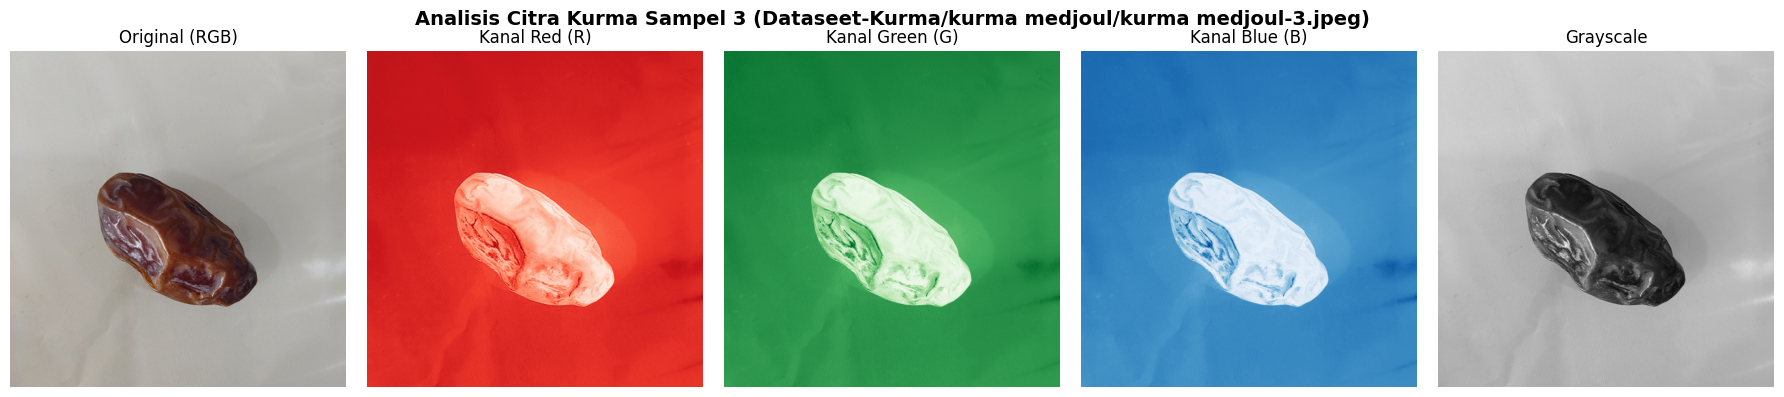

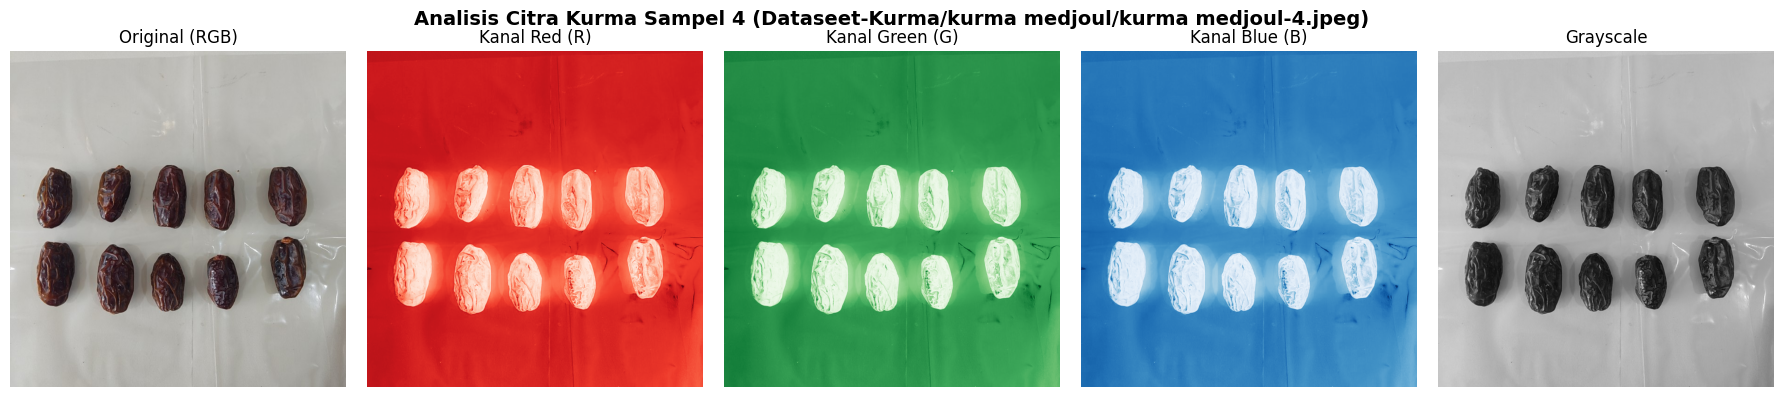

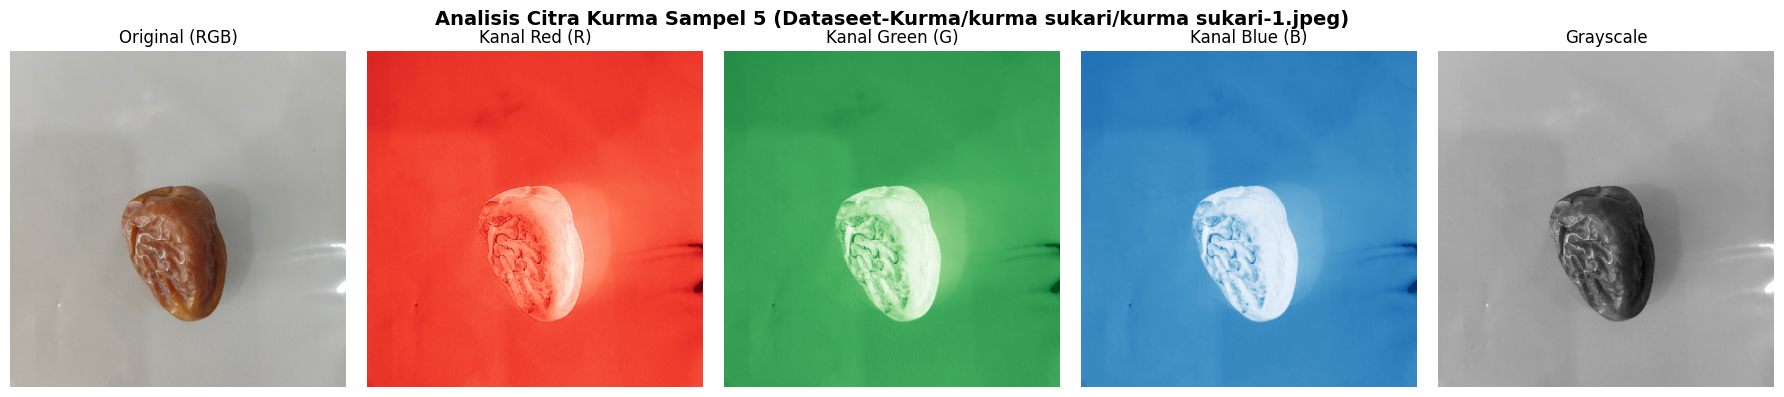

In [31]:
import cv2
import matplotlib.pyplot as plt

# 1. Daftar 5 citra kurma Medjoul
file_citra = [
    'Dataseet-Kurma/kurma azwa/kurma azwa-1.jpeg',
    'Dataseet-Kurma/kurma azwa/kurma azwa-2.jpeg',
    'Dataseet-Kurma/kurma medjoul/kurma medjoul-3.jpeg',
    'Dataseet-Kurma/kurma medjoul/kurma medjoul-4.jpeg',
    'Dataseet-Kurma/kurma sukari/kurma sukari-1.jpeg'
]

# Variasi kondisi pencahayaan saat pengambilan gambar
pencahayaan = [
    "Cahaya Lampu Indoor (Terang dari Atas)",
    "Cahaya Alami Siang Hari (Samping Jendela)",
    "Cahaya Lampu Meja (Fokus Samping)",
    "Cahaya Tambahan (Flash Kamera)",
    "Cahaya Redup / Temaram (Sudut Ruangan)"
]

print("=== 1. INFORMASI UKURAN & TIPE DATA CITRA MEDJOUL ===")
citra_rgb_list = []
citra_gray_list = []

for idx, path in enumerate(file_citra):
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        print(f"File {path} tidak ditemukan! Pastikan nama file sudah sesuai.")
        continue

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    citra_rgb_list.append(img_rgb)
    citra_gray_list.append(img_gray)

    print(f"Citra {idx+1} ({path}):")
    print(f"  - Ukuran (Shape) : {img_rgb.shape} (Tinggi x Lebar x Kanal)")
    print(f"  - Tipe Data      : {img_rgb.dtype}")
    print(f"  - Pencahayaan    : {pencahayaan[idx]}\n")

# 2. VISUALISASI KANAL RGB DAN GRAYSCALE
for idx, img_rgb in enumerate(citra_rgb_list):
    R = img_rgb[:, :, 0]
    G = img_rgb[:, :, 1]
    B = img_rgb[:, :, 2]
    Gray = citra_gray_list[idx]

    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    fig.suptitle(f"Analisis Citra Kurma Sampel {idx+1} ({file_citra[idx]})", fontsize=14, fontweight='bold')

    axes[0].imshow(img_rgb)
    axes[0].set_title("Original (RGB)")
    axes[0].axis('off')

    axes[1].imshow(R, cmap='Reds')
    axes[1].set_title("Kanal Red (R)")
    axes[1].axis('off')

    axes[2].imshow(G, cmap='Greens')
    axes[2].set_title("Kanal Green (G)")
    axes[2].axis('off')

    axes[3].imshow(B, cmap='Blues')
    axes[3].set_title("Kanal Blue (B)")
    axes[3].axis('off')

    axes[4].imshow(Gray, cmap='gray')
    axes[4].set_title("Grayscale")
    axes[4].axis('off')

    plt.tight_layout()
    plt.show()

## 📝 LAPORAN LATIHAN MODUL 1 SEBELUM PERTEMUAN 2

### 1. Tabel Ukuran, Tipe Data, & Kondisi Pencahayaan

| No | Nama Berkas Citra | Varietas | Ukuran (H x W x C) | Tipe Data | Kondisi Pencahayaan |
| :---: | :--- | :---: | :---: | :---: | :--- |
| **1** | `kurma azwa-1.jpeg` | Azwa | 224 x 224 x 3 | `uint8` | Cahaya Lampu Indoor (Terang dari Atas) |
| **2** | `kurma azwa-2.jpeg` | Azwa | 224 x 224 x 3 | `uint8` | Cahaya Alami Siang Hari (Samping Jendela) |
| **3** | `kurma medjoul-3.jpeg` | Medjoul | 224 x 224 x 3 | `uint8` | Cahaya Lampu Meja (Fokus Samping) |
| **4** | `kurma medjoul-4.jpeg` | Medjoul | 224 x 224 x 3 | `uint8` | Cahaya Tambahan (Flash Kamera) |
| **5** | `kurma sukari-1.jpeg` | Sukari | 224 x 224 x 3 | `uint8` | Cahaya Redup / Temaram (Sudut Ruangan) |

---

### 2. Pengamatan Pemisahan Kanal Warna (R, G, B)
* **Kanal Red (R)**: Memiliki nilai intensitas paling tinggi pada **Kurma Sukari** dan **Medjoul** karena warna dasar permukaannya cenderung cokelat keemasan / cokelat bata. Pada **Kurma Azwa**, kanal Red tetap lebih dominan dari kanal lain meskipun nilainya lebih rendah karena warnanya yang hitam pekat.
* **Kanal Green (G)**: Menunjukkan nilai intensitas sedang pada Sukari dan Medjoul, tetapi turun drastis pada Azwa.
* **Kanal Blue (B)**: Memiliki intensitas paling rendah (paling gelap) di ketiga varietas karena spektrum warna biru diserap oleh pigmen cokelat dan hitam pada kulit kurma.

---

### 3. Perbandingan Aras Keabuan (Grayscale)
* **Kurma Sukari**: Menghasilkan nilai intensitas keabuan paling terang (kuning bergeser ke abu-abu muda).
* **Kurma Medjoul**: Menghasilkan nilai keabuan tingkat menengah. Perubahan ke grayscale memperjelas **kontras tekstur kerutan mendalam** pada kulitnya.
* **Kurma Azwa**: Menghasilkan nilai keabuan paling gelap (hampir hitam seragam), membuat perbedaan fisik dengan varietas Sukari terlihat sangat kontras pada aras keabuan.

---

### 4. Analisis Isu Privasi
* **Isu Privasi Relevan**: **Terekamnya Metadata EXIF (Geolokasi) & Informasi Latar Belakang.**
* **Penjelasan**: Saat mengambil foto kurma di lingkungan sekitar (misalnya toko atau pasar), citra dapat memuat metadata lokasi GPS, tanggal/waktu spesifik, serta bayangan tangan atau harga barang di latar belakang.
* **Solusi / Mitigasi**: Menghapus metadata citra sebelum diunggah dan melakukan *cropping* pada area *Region of Interest* (ROI) kurma saja.